In [42]:
# SECTION 1: IMPORTING LIBRARIES

import os
import sys
import math
import json
from typing import List, Dict, Optional, Tuple

# For data handling
import pandas as pd
import numpy as np
import missingno as msno

# for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# For preparing and splitting the dataset
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# For model trainind and testing
from sklearn.linear_model import LogisticRegression

# Metrics to use evaluate model performance
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# To polish graphs and make look cleaner
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [43]:
# SECTION 2: LOADING THE CLEANED DATASET

df = pd.read_csv("pnw_training_corrected.csv")

# Display the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display the first five rows
display(df.head())

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check the data types and missing values
print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))


Dataset dimensions: (38579, 22)


,event_id,label,source_latitude_deg,source_longitude_deg,preferred_source_magnitude,source_depth_km,local_hour_sin,local_hour_cos,weekend,cb_crest_factor,...,nb_log10_sh_sz_rms_ratio_4_8hz,nb_envelope_rise_10_90_s_2_10hz,nb_envelope_excess_kurtosis_2_10hz,nb_log10_psd_power_1_5_over_5_15hz,geographic_fold,nb_log10_pz_sh_rms_ratio_4_8hz__n_stations,nb_log10_sh_sz_rms_ratio_4_8hz__n_stations,nb_envelope_rise_10_90_s_2_10hz__n_stations,nb_envelope_excess_kurtosis_2_10hz__n_stations,nb_log10_psd_power_1_5_over_5_15hz__n_stations
0,uw10547793,0,42.022,-122.097,1.5,6.319,-0.992810,0.119704,0,12.179417,...,1.040345,4.07,10.797078,-0.969816,4,1,1,1,1,1
1,uw10547878,0,42.105,-124.375,2.4,30.687,-0.316339,0.948646,1,5.191879,...,0.480488,1.45,4.102076,0.431430,2,1,1,1,1,1
2,uw10549468,0,47.612,-121.956,0.7,17.861,0.604831,-0.796354,0,5.542710,...,0.260246,4.63,1.901415,-0.143798,5,1,1,1,1,1
3,uw10549578,0,48.459,-119.543,2.9,2.684,0.536379,0.843977,0,6.678193,...,0.300007,14.50,3.993996,-0.263133,1,1,1,1,1,1
4,uw10549668,0,48.413,-122.286,3.0,18.139,0.187881,-0.982192,0,8.095458,...,0.316037,12.15,2.513362,0.090698,3,1,1,1,1,1



Column names:
['event_id', 'label', 'source_latitude_deg', 'source_longitude_deg', 'preferred_source_magnitude', 'source_depth_km', 'local_hour_sin', 'local_hour_cos', 'weekend', 'cb_crest_factor', 'cb_spectral_entropy', 'nb_log10_pz_sh_rms_ratio_4_8hz', 'nb_log10_sh_sz_rms_ratio_4_8hz', 'nb_envelope_rise_10_90_s_2_10hz', 'nb_envelope_excess_kurtosis_2_10hz', 'nb_log10_psd_power_1_5_over_5_15hz', 'geographic_fold', 'nb_log10_pz_sh_rms_ratio_4_8hz__n_stations', 'nb_log10_sh_sz_rms_ratio_4_8hz__n_stations', 'nb_envelope_rise_10_90_s_2_10hz__n_stations', 'nb_envelope_excess_kurtosis_2_10hz__n_stations', 'nb_log10_psd_power_1_5_over_5_15hz__n_stations']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 38579 entries, 0 to 38578
Data columns (total 22 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   event_id                                        38579 non-null

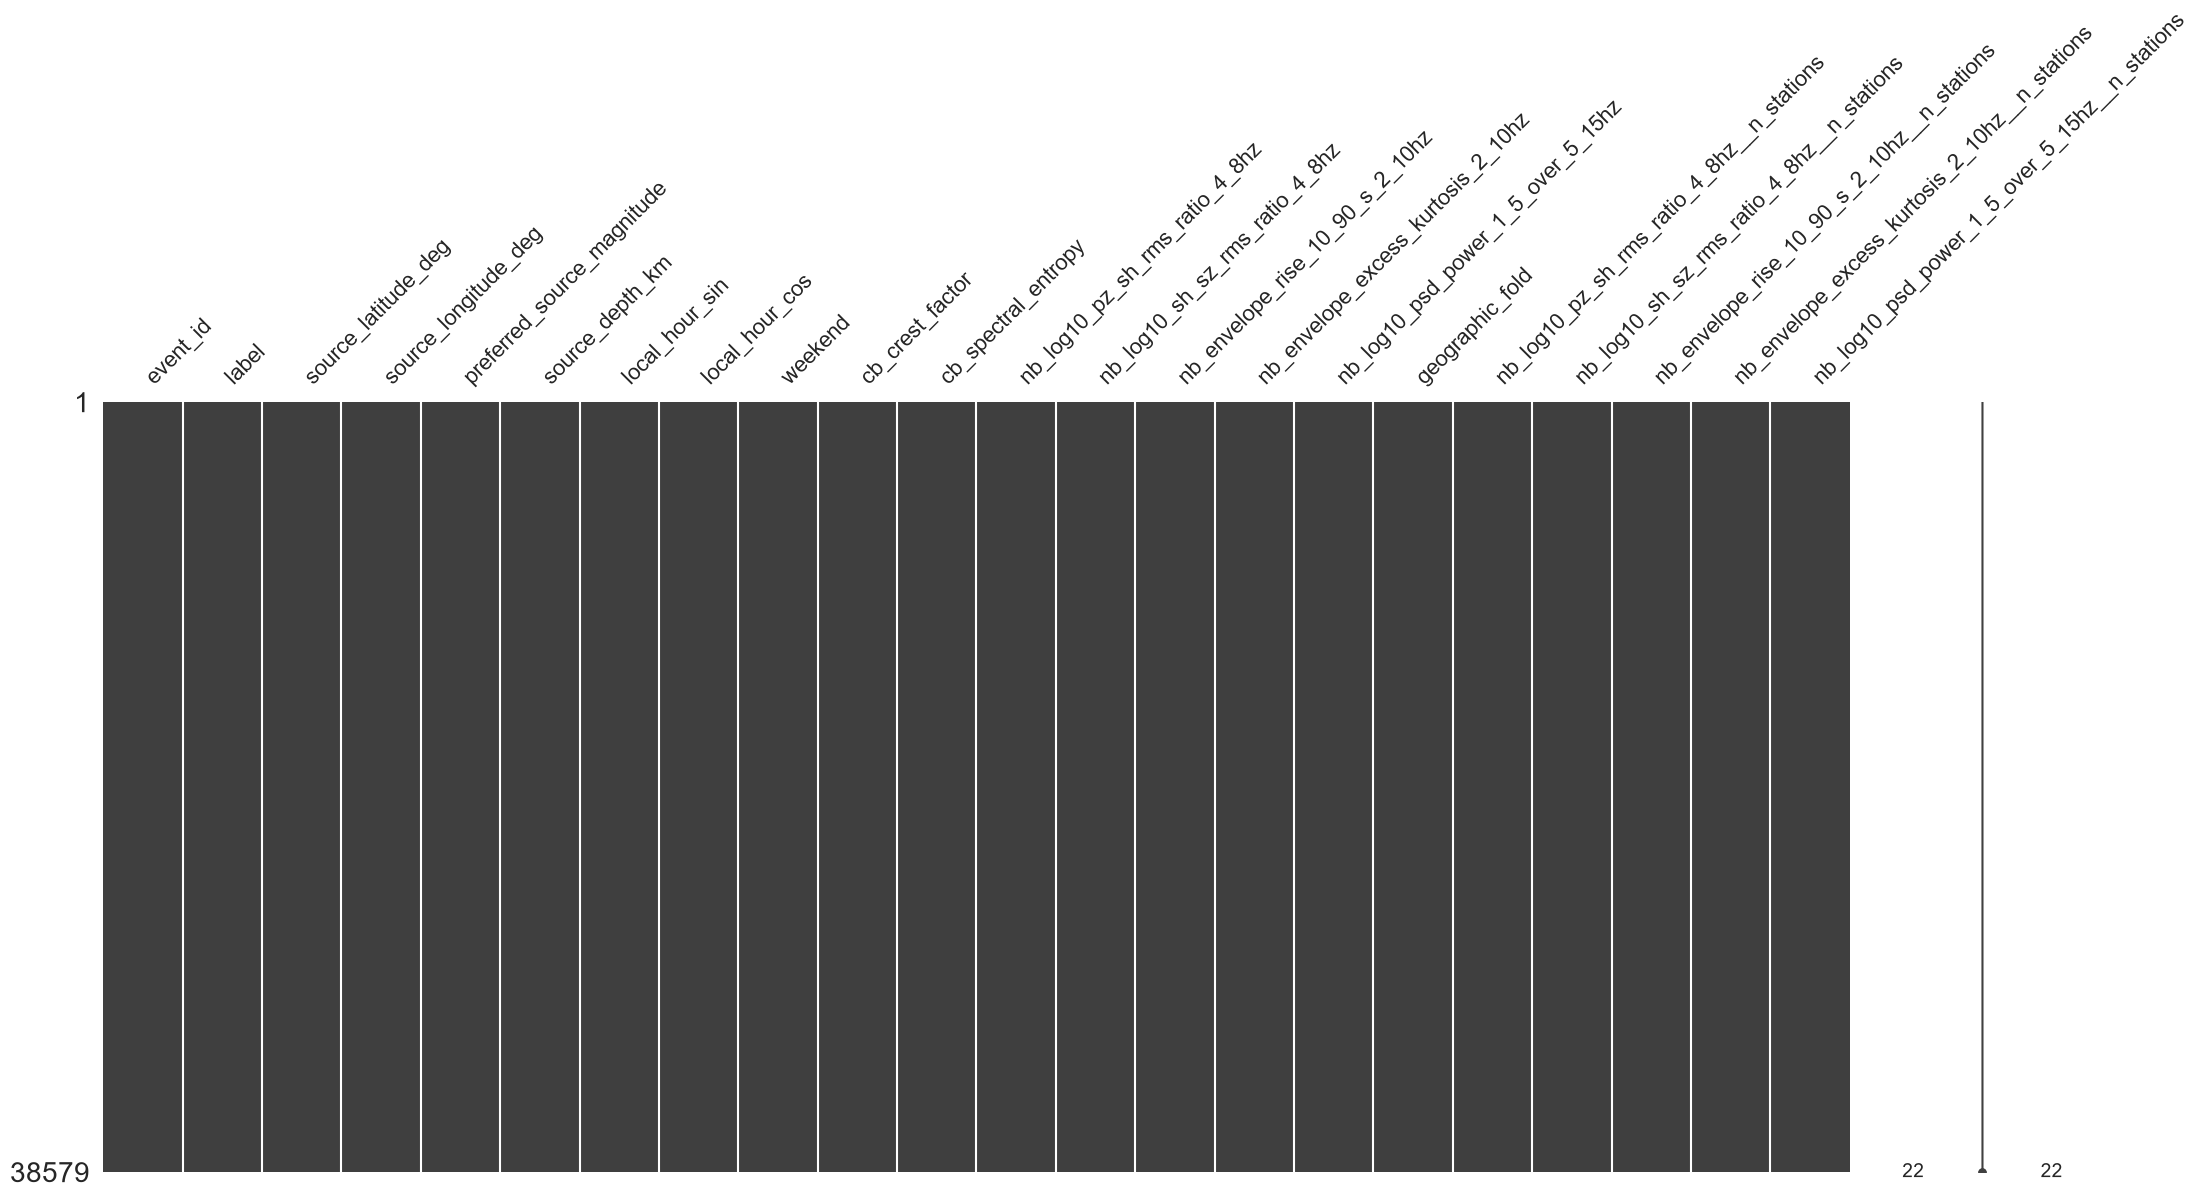

In [44]:
# VISUALIZING MISSINGNESS
msno.matrix(df)
plt.show()

In [45]:
# SECTION 3: CHECKING LABELS AND GROUPING

# Check how earthquakes and explosions are encoded
print("EVENT LABEL COUNTS:")
print(df["label"].value_counts().sort_index())

print("\nEVENT LABEL PROPORTIONS:")
print(df["label"].value_counts(normalize=True).sort_index())

# Check how many geographic groups we have
print("\nGEOGRAPHIC FOLD COUNTS:")
print(df["geographic_fold"].value_counts().sort_index())

print("\nNumber of geographic folds:",
      df["geographic_fold"].nunique())

# Check whether event IDs are unique
print("\nUNIQUE EVENT IDS:",
      df["event_id"].nunique())

print("\nDUPLICATE EVENT IDS:",
      df["event_id"].duplicated().sum())

# Check whether events within each geographic fold
# contain both earthquake and explosion labels
print("\nLABEL DISTRIBUTION BY GEOGRAPHIC FOLD:")
print(pd.crosstab(df["geographic_fold"], df["label"]))

# SEPARATING TRAINING AND TEST DATA

# Reserve geographic Fold 3 for final testing
TEST_FOLD = 3

# Folds 1, 2, 4 and 5 will be used for training
train_df = df[df["geographic_fold"] != TEST_FOLD].copy()

# Fold 3 will remain untouched until final evaluation
test_df = df[df["geographic_fold"] == TEST_FOLD].copy()

# Check the resulting split
print("\nTRAINING DATA:")
print("Number of events:", len(train_df))
print("Geographic folds:",
      sorted(train_df["geographic_fold"].unique()))

print("\nFINAL TEST DATA:")
print("Number of events:", len(test_df))
print("Geographic folds:",
      sorted(test_df["geographic_fold"].unique()))


EVENT LABEL COUNTS:
label
0    32912
1     5667
Name: count, dtype: int64

EVENT LABEL PROPORTIONS:
label
0    0.853107
1    0.146893
Name: proportion, dtype: float64

GEOGRAPHIC FOLD COUNTS:
geographic_fold
1    7724
2    7719
3    7712
4    7713
5    7711
Name: count, dtype: int64

Number of geographic folds: 5

UNIQUE EVENT IDS: 38579

DUPLICATE EVENT IDS: 0

LABEL DISTRIBUTION BY GEOGRAPHIC FOLD:
label               0     1
geographic_fold            
1                6586  1138
2                6584  1135
3                6581  1131
4                6581  1132
5                6580  1131

TRAINING DATA:
Number of events: 30867
Geographic folds: [np.int64(1), np.int64(2), np.int64(4), np.int64(5)]

FINAL TEST DATA:
Number of events: 7712
Geographic folds: [np.int64(3)]


In [46]:
# SECTION 4: SELECTING THE FEATURES

# The column the model will predict
target = "label"

# Catalog information, excluding depth
catalog_features = [
    "source_latitude_deg",
    "source_longitude_deg",
    "preferred_source_magnitude",
    "local_hour_sin",
    "local_hour_cos",
    "weekend"
]

# Depth is kept separate to measure its contribution
depth_feature = ["source_depth_km"]

# Waveform measurements
waveform_features = [
    "cb_crest_factor",
    "cb_spectral_entropy",
    "nb_log10_pz_sh_rms_ratio_4_8hz",
    "nb_log10_sh_sz_rms_ratio_4_8hz",
    "nb_envelope_rise_10_90_s_2_10hz",
    "nb_envelope_excess_kurtosis_2_10hz",
    "nb_log10_psd_power_1_5_over_5_15hz"
]

# Five experiments
experiments = {
    "A - Catalog only": catalog_features,

    "B - Waveform only": waveform_features,

    "C - Catalog + Waveforms":
        catalog_features + waveform_features,

    "D - Catalog + Depth":
        catalog_features + depth_feature,

    "E - Catalog + Depth + Waveforms":
        catalog_features + depth_feature + waveform_features

    
}

# Checking that all selected columns exist
for name, features in experiments.items():
    missing = [col for col in features if col not in df.columns]

    if missing:
        raise ValueError(f"{name} has missing columns: {missing}")

    print(f"{name}: {len(features)} features")

print("\nFeature selection complete!")


A - Catalog only: 6 features
B - Waveform only: 7 features
C - Catalog + Waveforms: 13 features
D - Catalog + Depth: 7 features
E - Catalog + Depth + Waveforms: 14 features

Feature selection complete!


In [47]:
# SECTION 5: TRAINING THE LOGISTIC REGRESSION MODEL

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# STEP 1: PREPARE THE TRAINING DATA

# Use training data only.
# Fold 3 remains untouched for final testing.

y = train_df[target]
groups = train_df["geographic_fold"]

# Four-fold geographic cross-validation
cv = GroupKFold(n_splits=4)

# Store results and predictions
results = []
fold_results = []
all_predictions = {}

# STEP 2: RUN THE FIVE EXPERIMENTS

for experiment_name, features in experiments.items():

    print("\nRunning:", experiment_name)

    # Select features from training data only
    X = train_df[features]

    # Store out-of-fold predictions for training events
    oof_predictions = np.zeros(len(train_df))

    fold_scores = []

    # Train on three geographic folds
    # Validate on the remaining geographic fold
    for train_idx, val_idx in cv.split(X, y, groups):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Build preprocessing and logistic regression pipeline
        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),

            ("scaler", StandardScaler()),

            ("logistic", LogisticRegression(
                max_iter=2000,
                class_weight=None,
                random_state=42
            ))
        ])

        # Train the model
        model.fit(X_train, y_train)

        # Predict explosion probabilities
        probabilities = model.predict_proba(X_val)[:, 1]

        # Save predictions for each validation event
        oof_predictions[val_idx] = probabilities

        # Calculate average precision for this fold
        fold_ap = average_precision_score(
            y_val, probabilities
        )

        fold_scores.append(fold_ap)

         # Identify which geographic fold was validated
        validation_group = groups.iloc[val_idx].unique()[0]
        
        # Save individual fold results
        fold_results.append({
        "Experiment": experiment_name,
        "Fold": validation_group,
        "Average Precision": fold_ap
        })

        print(
            f"Geographic Fold {validation_group}: "
            f"Average Precision = {fold_ap:.4f}"
        )

    # STEP 3: CALCULATE OVERALL PERFORMANCE

    # Convert probabilities into predicted labels
    # Using a classification threshold of 0.5
    predicted_labels = (oof_predictions >= 0.5).astype(int)

    # Calculate metrics using all out-of-fold predictions
    ap = average_precision_score(y, oof_predictions)

    precision = precision_score(
        y, predicted_labels, zero_division=0
    )

    recall = recall_score(
        y, predicted_labels, zero_division=0
    )

    f1 = f1_score(
        y, predicted_labels, zero_division=0
    )

    roc_auc = roc_auc_score(
        y, oof_predictions
    )

    # STEP 4: SAVE THE RESULTS

    results.append({
        "Experiment": experiment_name,
        "Average Precision": ap,
        "Mean Fold AP": np.mean(fold_scores),
        "Fold AP Std": np.std(fold_scores),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": roc_auc
    })

    all_predictions[experiment_name] = oof_predictions

# STEP 5: DISPLAY RESULTS

fold_results_df = pd.DataFrame(fold_results)

results_df = pd.DataFrame(results)

print("\n========== LOGISTIC REGRESSION RESULTS ==========")

display(results_df.round(4))



Running: A - Catalog only
Geographic Fold 1: Average Precision = 0.5764
Geographic Fold 2: Average Precision = 0.4948
Geographic Fold 4: Average Precision = 0.4507
Geographic Fold 5: Average Precision = 0.4643

Running: B - Waveform only
Geographic Fold 1: Average Precision = 0.5888
Geographic Fold 2: Average Precision = 0.4511
Geographic Fold 4: Average Precision = 0.7240
Geographic Fold 5: Average Precision = 0.7593

Running: C - Catalog + Waveforms
Geographic Fold 1: Average Precision = 0.7176
Geographic Fold 2: Average Precision = 0.7977
Geographic Fold 4: Average Precision = 0.8233
Geographic Fold 5: Average Precision = 0.8403

Running: D - Catalog + Depth
Geographic Fold 1: Average Precision = 0.8044
Geographic Fold 2: Average Precision = 0.8227
Geographic Fold 4: Average Precision = 0.8625
Geographic Fold 5: Average Precision = 0.8784

Running: E - Catalog + Depth + Waveforms
Geographic Fold 1: Average Precision = 0.7616
Geographic Fold 2: Average Precision = 0.8776
Geographic 

,Experiment,Average Precision,Mean Fold AP,Fold AP Std,Precision,Recall,F1 Score,ROC AUC
0,A - Catalog only,0.4913,0.4966,0.0488,0.5702,0.3135,0.4046,0.8853
1,B - Waveform only,0.6214,0.6308,0.1217,0.7009,0.4773,0.5679,0.9254
2,C - Catalog + Waveforms,0.7849,0.7947,0.0470,0.8167,0.7152,0.7626,0.9674
3,D - Catalog + Depth,0.8315,0.8420,0.0297,0.8142,0.8366,0.8253,0.9723
4,E - Catalog + Depth + Waveforms,0.8467,0.8616,0.0596,0.8639,0.8620,0.8629,0.9818


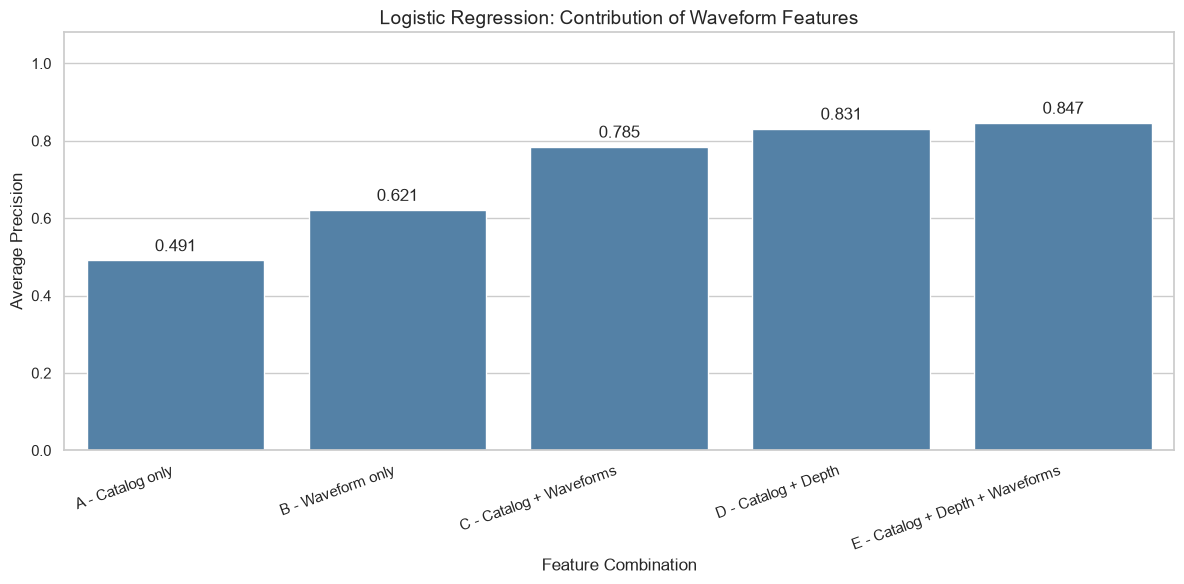

In [48]:
# SECTION 6: PERFORMANCE COMPARISON GRAPH

# Compare average precision across all five experiments

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=results_df,
    x="Experiment",
    y="Average Precision",
    color="steelblue"
)

# Add the numerical values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=4
    )

plt.title(
    "Logistic Regression: Contribution of Waveform Features",
    fontsize=14
)

plt.ylabel("Average Precision")
plt.xlabel("Feature Combination")
plt.ylim(0, 1.08)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

# Save graph for the presentation
plt.savefig(
    "logistic_regression_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


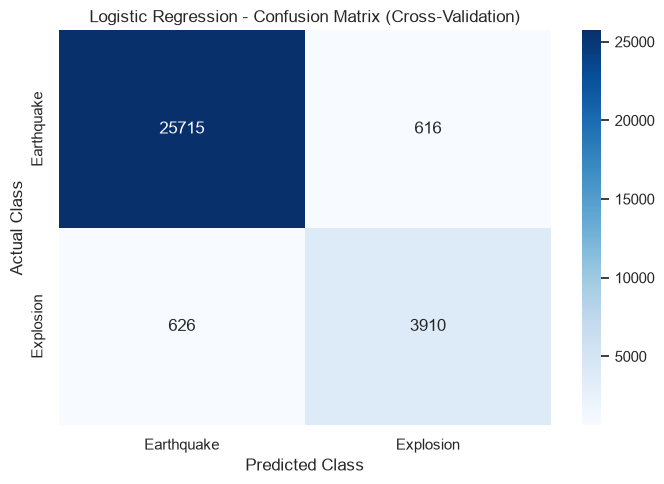

In [49]:
# SECTION 7: CONFUSION MATRIX

# Use the model with catalog, depth and waveform features
best_experiment = "E - Catalog + Depth + Waveforms"

# Convert predicted probabilities into classes
best_predictions = (
    all_predictions[best_experiment] >= 0.5
).astype(int)

# Calculate the confusion matrix using training CV predictions
cm = confusion_matrix(y, best_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Earthquake", "Explosion"],
    yticklabels=["Earthquake", "Explosion"]
)

plt.title(
    "Logistic Regression - Confusion Matrix (Cross-Validation)"
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    "logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [50]:
# SECTION 8: EXPORTING THE RESULTS

# 1. Save the performance comparison
# Contains all five experiments and their evaluation metrics

results_df.to_csv(
    "logistic_regression_results.csv",
    index=False
)


# 2. Save the confusion matrix
# Shows correct and incorrect classifications

pd.DataFrame(
    cm,
    index=["Actual Earthquake", "Actual Explosion"],
    columns=["Predicted Earthquake", "Predicted Explosion"]
).to_csv(
    "logistic_regression_confusion_matrix.csv"
)


# 3. Save individual fold results
# Allows us to compare model consistency across geographic folds

fold_results_df.to_csv(
    "logistic_regression_fold_results.csv",
    index=False
)


print("All results successfully exported!")

print("\nFiles created:")
print("1. logistic_regression_results.csv")
print("2. logistic_regression_confusion_matrix.csv")
print("3. logistic_regression_fold_results.csv")


All results successfully exported!

Files created:
1. logistic_regression_results.csv
2. logistic_regression_confusion_matrix.csv
3. logistic_regression_fold_results.csv


In [51]:
# SECTION 9: FINAL TEST EVALUATION ON HELD-OUT FOLD 3
# Evaluate all five Logistic Regression experiments

from sklearn.metrics import accuracy_score

# Store final test results
final_test_results = []

# Store predictions for confusion matrices
test_predictions_all = {}

# Prepare training and test labels
y_train = train_df[target]
y_test = test_df[target]

# Loop through all five feature experiments
for experiment_name, features in experiments.items():

    print("\nRunning:", experiment_name)

    # STEP 1: PREPARE FEATURES

    X_train = train_df[features]
    X_test = test_df[features]

    # STEP 2: BUILD LOGISTIC REGRESSION PIPELINE

    final_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),

        ("scaler", StandardScaler()),

        ("logistic", LogisticRegression(
            max_iter=2000,
            class_weight=None,
            random_state=42
        ))
    ])

    # STEP 3: TRAIN ON ALL FOUR TRAINING FOLDS

    final_model.fit(X_train, y_train)

    # STEP 4: PREDICT ON UNSEEN TEST FOLD 3

    test_probabilities = final_model.predict_proba(X_test)[:, 1]

    # Use default classification threshold of 0.5
    test_predictions = (test_probabilities >= 0.5).astype(int)

    # STEP 5: CALCULATE EVALUATION METRICS

    test_ap = average_precision_score(
        y_test, test_probabilities
    )

    test_precision = precision_score(
        y_test, test_predictions, zero_division=0
    )

    test_recall = recall_score(
        y_test, test_predictions, zero_division=0
    )

    test_f1 = f1_score(
        y_test, test_predictions, zero_division=0
    )

    test_roc_auc = roc_auc_score(
        y_test, test_probabilities
    )

    test_accuracy = accuracy_score(
        y_test, test_predictions
    )

    # STEP 6: SAVE RESULTS

    final_test_results.append({
        "Experiment": experiment_name,
        "Average Precision": test_ap,
        "Precision": test_precision,
        "Recall": test_recall,
        "F1 Score": test_f1,
        "ROC AUC": test_roc_auc,
        "Accuracy": test_accuracy
    })

    # Save predictions for later confusion matrices
    test_predictions_all[experiment_name] = {
        "probabilities": test_probabilities,
        "predictions": test_predictions
    }

    # Display individual experiment results
    print(f"Average Precision: {test_ap:.4f}")
    print(f"Precision: {test_precision:.4f}")
    print(f"Recall: {test_recall:.4f}")
    print(f"F1 Score: {test_f1:.4f}")
    print(f"ROC AUC: {test_roc_auc:.4f}")
    print(f"Accuracy: {test_accuracy:.4f}")


# STEP 7: CREATE FINAL COMPARISON TABLE

final_test_results_df = pd.DataFrame(final_test_results)

print("\n========== FINAL TEST RESULTS (FOLD 3) ==========")

display(final_test_results_df.round(4))



Running: A - Catalog only
Average Precision: 0.4354
Precision: 0.4511
Recall: 0.2122
F1 Score: 0.2886
ROC AUC: 0.8821
Accuracy: 0.8466

Running: B - Waveform only
Average Precision: 0.8491
Precision: 0.8485
Recall: 0.6835
F1 Score: 0.7571
ROC AUC: 0.9709
Accuracy: 0.9357

Running: C - Catalog + Waveforms
Average Precision: 0.8605
Precision: 0.8547
Recall: 0.8064
F1 Score: 0.8298
ROC AUC: 0.9743
Accuracy: 0.9515

Running: D - Catalog + Depth
Average Precision: 0.8372
Precision: 0.8481
Recall: 0.8541
F1 Score: 0.8511
ROC AUC: 0.9795
Accuracy: 0.9562

Running: E - Catalog + Depth + Waveforms
Average Precision: 0.9102
Precision: 0.9028
Recall: 0.8948
F1 Score: 0.8988
ROC AUC: 0.9887
Accuracy: 0.9704

========== FINAL TEST RESULTS (FOLD 3) ==========


,Experiment,Average Precision,Precision,Recall,F1 Score,ROC AUC,Accuracy
0,A - Catalog only,0.4354,0.4511,0.2122,0.2886,0.8821,0.8466
1,B - Waveform only,0.8491,0.8485,0.6835,0.7571,0.9709,0.9357
2,C - Catalog + Waveforms,0.8605,0.8547,0.8064,0.8298,0.9743,0.9515
3,D - Catalog + Depth,0.8372,0.8481,0.8541,0.8511,0.9795,0.9562
4,E - Catalog + Depth + Waveforms,0.9102,0.9028,0.8948,0.8988,0.9887,0.9704


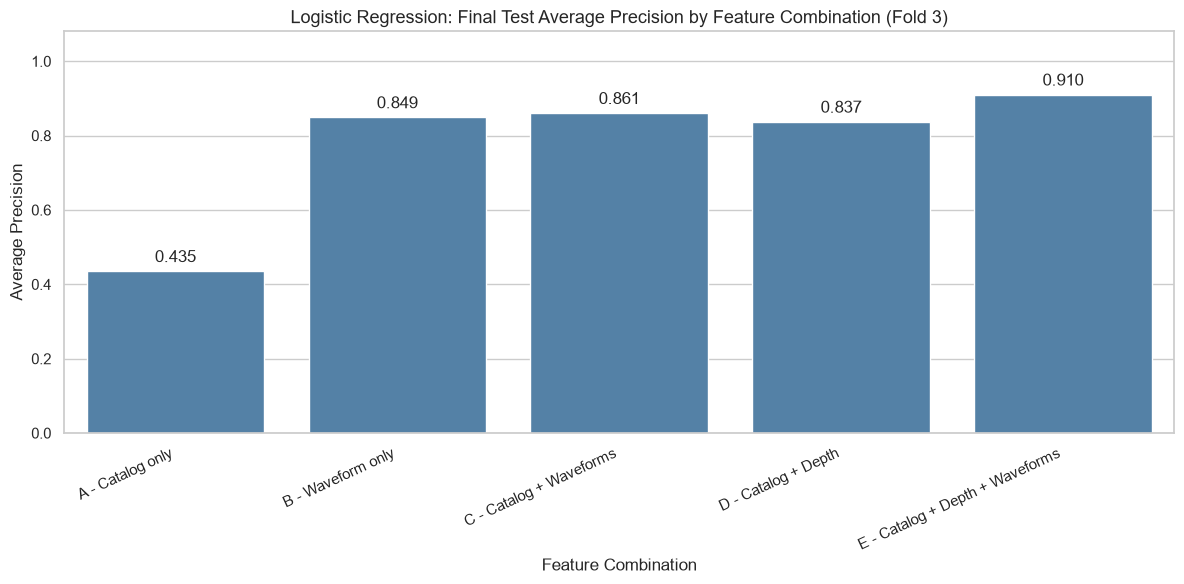

In [52]:
# SECTION 10: FINAL TEST PERFORMANCE COMPARISON

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=final_test_results_df,
    x="Experiment",
    y="Average Precision",
    color="steelblue"
)

# Add numerical values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=4
    )

plt.title(
    "Logistic Regression: Final Test Average Precision by Feature Combination (Fold 3)",
    fontsize=13
)

plt.ylabel("Average Precision")
plt.xlabel("Feature Combination")
plt.ylim(0, 1.08)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()

# Save graph for presentation
plt.savefig(
    "logistic_regression_final_test_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


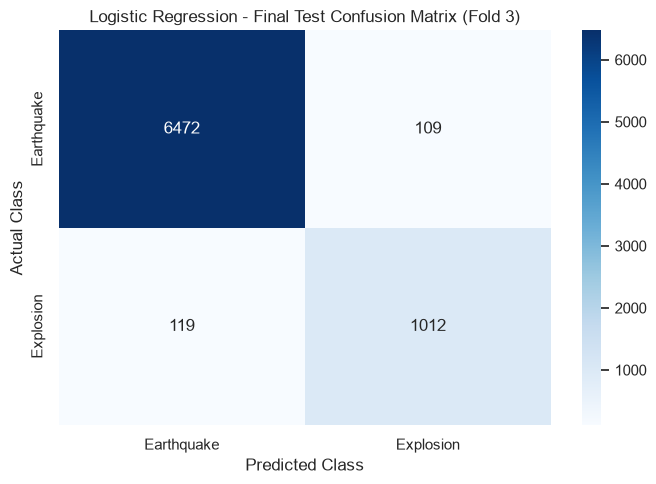

In [53]:
# SECTION 11: FINAL TEST CONFUSION MATRIX
# Best feature combination: Experiment E

best_experiment = "E - Catalog + Depth + Waveforms"

# Retrieve predictions from Section 8
best_test_predictions = (
    test_predictions_all[best_experiment]["predictions"]
)

# Calculate confusion matrix using fold 3
cm_test = confusion_matrix(y_test, best_test_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Earthquake", "Explosion"],
    yticklabels=["Earthquake", "Explosion"]
)

plt.title(
    "Logistic Regression - Final Test Confusion Matrix (Fold 3)"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    "logistic_regression_final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



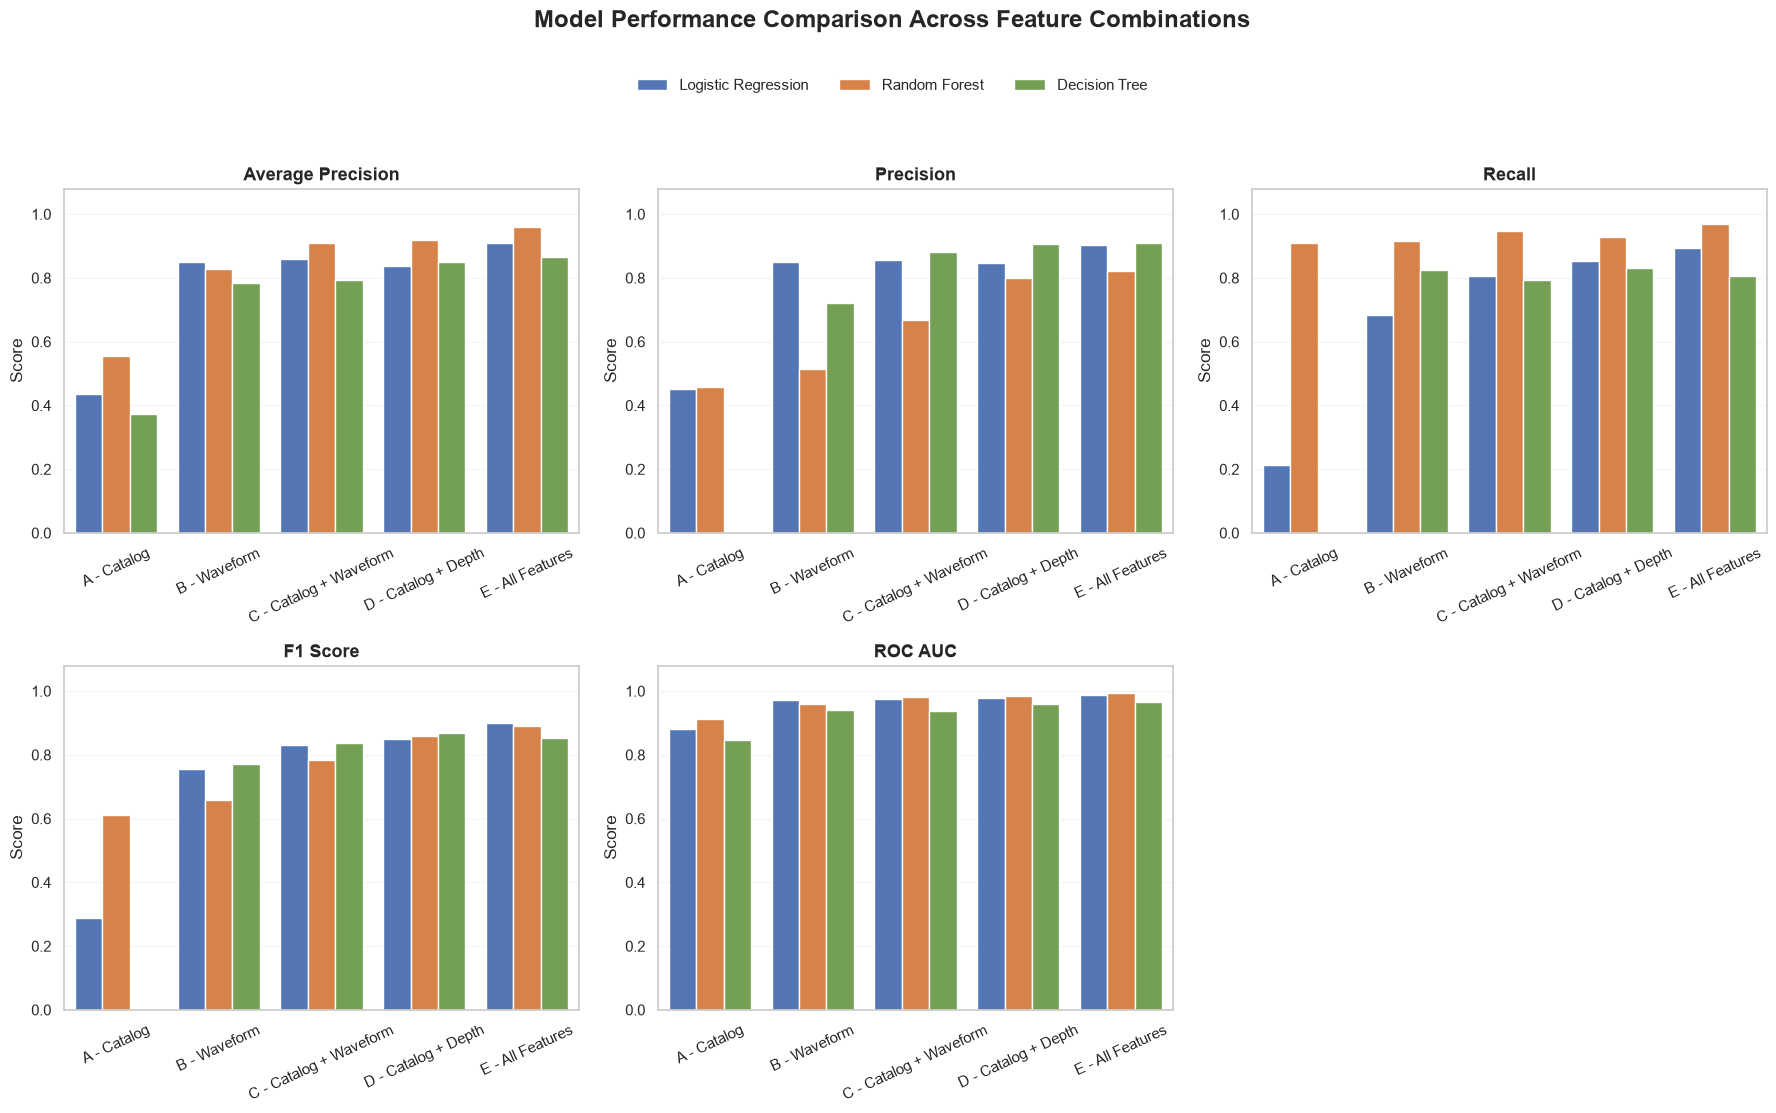

In [54]:

# SECTION 11: COMPARISON OF ALL THREE MODELS
# Compare all five feature experiments

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Store results from all three models
comparison_data = [
    # Logistic Regression
    ["A - Catalog only", "Logistic Regression", 0.4354, 0.4511, 0.2122, 0.2886, 0.8821],
    ["B - Waveform only", "Logistic Regression", 0.8491, 0.8485, 0.6835, 0.7571, 0.9709],
    ["C - Catalog + Waveforms", "Logistic Regression", 0.8605, 0.8547, 0.8064, 0.8298, 0.9743],
    ["D - Catalog + Depth", "Logistic Regression", 0.8372, 0.8481, 0.8541, 0.8511, 0.9795],
    ["E - Catalog + Depth + Waveforms", "Logistic Regression", 0.9102, 0.9028, 0.8948, 0.8988, 0.9887],

    # Random Forest
    ["A - Catalog only", "Random Forest", 0.556, 0.459, 0.911, 0.611, 0.913],
    ["B - Waveform only", "Random Forest", 0.829, 0.513, 0.916, 0.658, 0.958],
    ["C - Catalog + Waveforms", "Random Forest", 0.910, 0.668, 0.947, 0.783, 0.981],
    ["D - Catalog + Depth", "Random Forest", 0.919, 0.800, 0.929, 0.860, 0.986],
    ["E - Catalog + Depth + Waveforms", "Random Forest", 0.960, 0.822, 0.968, 0.889, 0.993],

    # Decision Tree
    ["A - Catalog only", "Decision Tree", 0.373, 0.0, 0.0, 0.0, 0.845],
    ["B - Waveform only", "Decision Tree", 0.784, 0.722, 0.825, 0.770, 0.940],
    ["C - Catalog + Waveforms", "Decision Tree", 0.793, 0.882, 0.795, 0.836, 0.936],
    ["D - Catalog + Depth", "Decision Tree", 0.849, 0.906, 0.831, 0.867, 0.958],
    ["E - Catalog + Depth + Waveforms", "Decision Tree", 0.865, 0.908, 0.807, 0.854, 0.965]
]

columns = [
    "Experiment",
    "Model",
    "Average Precision",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

comparison_df = pd.DataFrame(comparison_data, columns=columns)

# Shorter labels for plotting
experiment_labels = {
    "A - Catalog only": "A - Catalog",
    "B - Waveform only": "B - Waveform",
    "C - Catalog + Waveforms": "C - Catalog + Waveform",
    "D - Catalog + Depth": "D - Catalog + Depth",
    "E - Catalog + Depth + Waveforms": "E - All Features"
}

comparison_df["Experiment"] = comparison_df["Experiment"].map(experiment_labels)

# Define plotting order
experiment_order = [
    "A - Catalog",
    "B - Waveform",
    "C - Catalog + Waveform",
    "D - Catalog + Depth",
    "E - All Features"
]

model_order = [
    "Logistic Regression",
    "Random Forest",
    "Decision Tree"
]

metrics = [
    "Average Precision",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

# Model colors
palette = {
    "Logistic Regression": "#4472C4",
    "Random Forest": "#ED7D31",
    "Decision Tree": "#70AD47"
}

# Create five comparison plots
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

axes = axes.flatten()

for i, metric in enumerate(metrics):

    ax = axes[i]

    sns.barplot(
        data=comparison_df,
        x="Experiment",
        y=metric,
        hue="Model",
        order=experiment_order,
        hue_order=model_order,
        palette=palette,
        ax=ax
    )

    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.08)

    ax.tick_params(axis="x", rotation=25)

    ax.legend_.remove()

    ax.grid(axis="y", alpha=0.2)

# Remove unused sixth panel
fig.delaxes(axes[5])

# Add one shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.96),
    frameon=False
)

fig.suptitle(
    "Model Performance Comparison Across Feature Combinations",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout(rect=[0, 0, 1, 0.92])

plt.savefig(
    "all_models_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


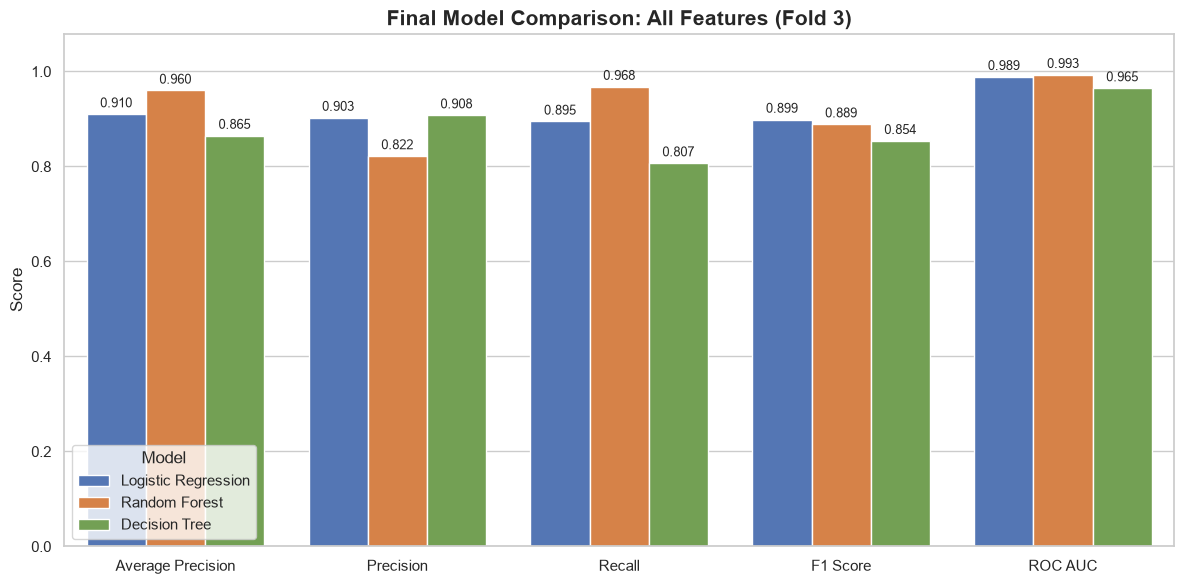

In [55]:
# SECTION 12: FINAL MODEL COMPARISON
# All features: Catalog + Depth + Waveforms

experiment_e = comparison_df[
    comparison_df["Experiment"] == "E - All Features"
]

metrics_to_plot = [
    "Average Precision",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

plot_data = experiment_e.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model",
    hue_order=model_order,
    palette=palette
)

ax.set_title(
    "Final Model Comparison: All Features (Fold 3)",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.08)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    "final_model_comparison_all_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


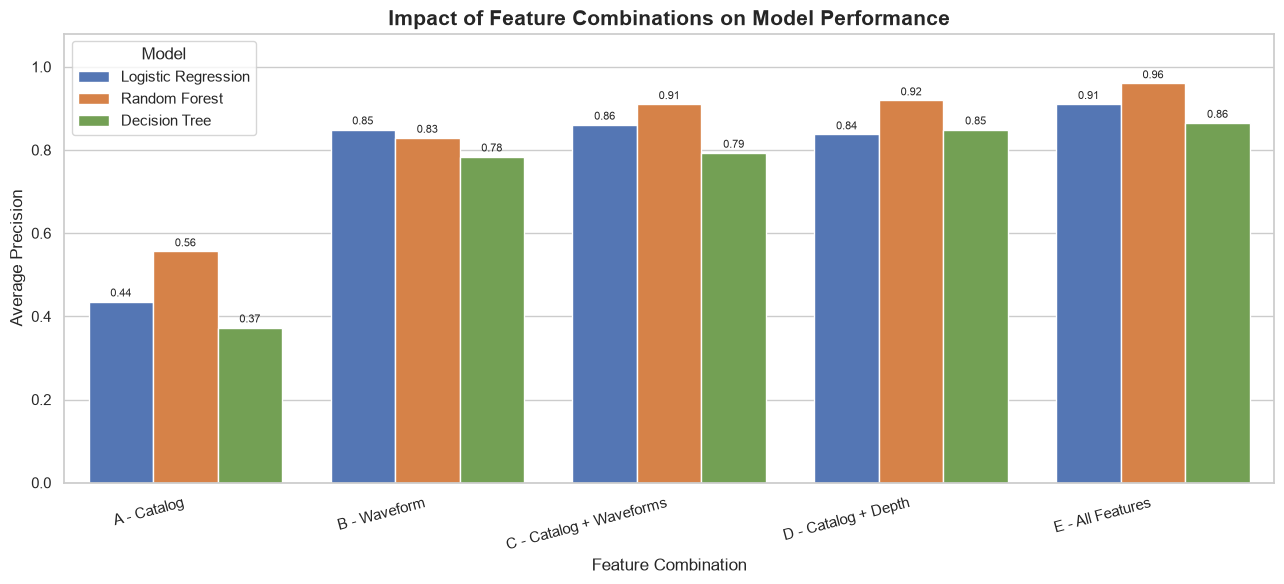

In [62]:

# PLOT 1: IMPACT OF FEATURE COMBINATIONS
# Average Precision across all three models

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

comparison_data = [
    ["A - Catalog", "Logistic Regression", 0.4354],
    ["B - Waveform", "Logistic Regression", 0.8491],
    ["C - Catalog + Waveforms", "Logistic Regression", 0.8605],
    ["D - Catalog + Depth", "Logistic Regression", 0.8372],
    ["E - All Features", "Logistic Regression", 0.9102],

    ["A - Catalog", "Random Forest", 0.556],
    ["B - Waveform", "Random Forest", 0.829],
    ["C - Catalog + Waveforms", "Random Forest", 0.910],
    ["D - Catalog + Depth", "Random Forest", 0.919],
    ["E - All Features", "Random Forest", 0.960],

    ["A - Catalog", "Decision Tree", 0.373],
    ["B - Waveform", "Decision Tree", 0.784],
    ["C - Catalog + Waveforms", "Decision Tree", 0.793],
    ["D - Catalog + Depth", "Decision Tree", 0.849],
    ["E - All Features", "Decision Tree", 0.865]
]

df_plot = pd.DataFrame(
    comparison_data,
    columns=["Experiment", "Model", "Average Precision"]
)

model_order = [
    "Logistic Regression",
    "Random Forest",
    "Decision Tree"
]

palette = {
    "Logistic Regression": "#4472C4",
    "Random Forest": "#ED7D31",
    "Decision Tree": "#70AD47"
}

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=df_plot,
    x="Experiment",
    y="Average Precision",
    hue="Model",
    hue_order=model_order,
    palette=palette
)

ax.set_title(
    "Impact of Feature Combinations on Model Performance",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Average Precision")
ax.set_xlabel("Feature Combination")
ax.set_ylim(0, 1.08)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=2,
    fontsize=8
)

for container in ax.containers[1:]:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=2,
        fontsize=8
    )

plt.xticks(rotation=15, ha="right")
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    "plot1_feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


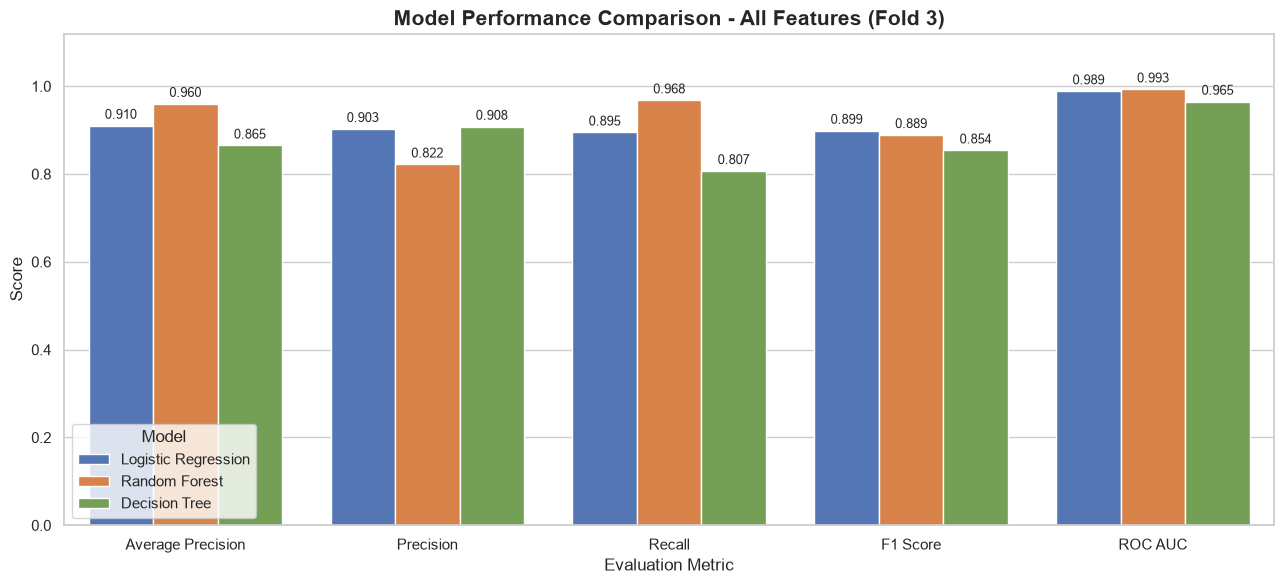

In [63]:
# PLOT 2: COMPARISON OF ALL THREE MODELS
# Experiment E - Catalog + Depth + Waveforms

model_results = [
    ["Logistic Regression", 0.9102, 0.9028, 0.8948, 0.8988, 0.9887],
    ["Random Forest",       0.9600, 0.8220, 0.9680, 0.8890, 0.9930],
    ["Decision Tree",       0.8650, 0.9080, 0.8070, 0.8540, 0.9650]
]

columns = [
    "Model",
    "Average Precision",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

model_df = pd.DataFrame(
    model_results,
    columns=columns
)

# Convert metrics into long format for plotting
plot_df = model_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model",
    hue_order=model_order,
    palette=palette
)

ax.set_title(
    "Model Performance Comparison - All Features (Fold 3)",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metric")
ax.set_ylim(0, 1.12)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    "plot2_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
